# When do 80% complaint intervals miss?
Project 04. Run the full replay with `python run.py` first. This notebook inspects the saved outputs and recomputes observed coverage.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
r = Path('results')
manifest = json.loads(Path('data/source_manifest.json').read_text())
print({k: manifest[k] for k in ['counts', 'absent_calendar_days', 'retrieved_at_utc']})

{'counts': 1280589, 'absent_calendar_days': 8, 'retrieved_at_utc': '2026-11-16T16:33:22.993601+00:00'}


## Issue-time boundaries
A Monday forecast can use counts through the prior Sunday under the zero-lag assumption. A four-week forecast targets the week starting three Mondays later. An error becomes eligible the Monday after the target week closes, with additional delay in the sensitivity replay.

In [2]:
p = pd.read_csv(r/'predictions.csv', parse_dates=['origin','target','latest_score_available','latest_feature_week'])
assert (p.latest_score_available <= p.origin).all()
assert (p.latest_feature_week < p.origin).all()
print(p[['origin','target','horizon','latest_score_available']].drop_duplicates().head())
display(pd.read_csv(r/'development.csv'))

      origin     target  horizon latest_score_available
0 2025-10-27 2025-10-27        1             2019-12-30
1 2025-11-03 2025-11-03        1             2019-12-30
2 2025-11-10 2025-11-10        1             2019-12-30
3 2025-11-17 2025-11-17        1             2019-12-30
4 2025-11-24 2025-11-24        1             2019-12-30


,gain,n,mean_score
0,0.01,288,1647.984375
1,0.06,288,1669.258681
2,0.03,288,1719.170139


## Calibration and evaluation
The recent mean is constant across interval methods at each origin. The frozen and rolling references hold alpha at 0.2. The adaptive variant updates alpha after earlier intervals resolve and clips it to a finite range. The score adds width and a penalty for either tail miss. Smaller scores are better.

sum  count      mean
horizon method                        
1       adaptive   44     54  0.814815
        frozen     40     54  0.740741
        rolling    43     54  0.796296
4       adaptive   42     54  0.777778
        frozen     40     54  0.740741
        rolling    42     54  0.777778

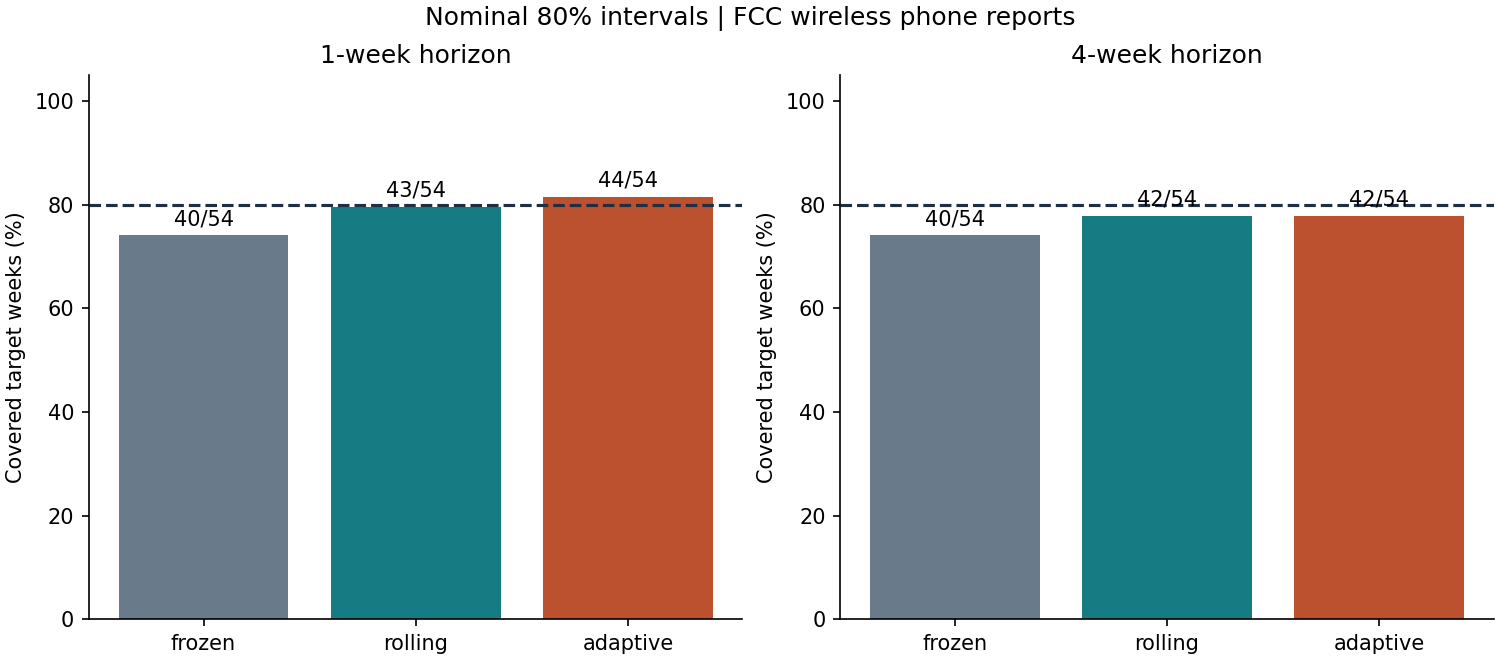

In [3]:
covered = p.actual.between(p.lower,p.upper)
assert (covered == p.covered).all()
display(p.assign(checked=covered).groupby(['horizon','method']).checked.agg(['sum','count','mean']))
display(Image(filename=str(r/'coverage.png')))

## Look past aggregate coverage
Inspect period and direction of misses. Moving-block draws pair methods on the same target weeks. The central 95% resampling ranges condition on this replay and do not establish coverage or statistical significance under arbitrary shift.

,horizon,method,period,n,covered,coverage,width,score,upper_misses,lower_misses
0,1,adaptive,first_26,26,21,0.807692,1847.528846,4700.509615,4,1
1,1,adaptive,remaining,28,23,0.821429,1842.553571,4890.053571,5,0
2,1,frozen,first_26,26,19,0.730769,1506.538462,4061.346154,6,1
3,1,frozen,remaining,28,21,0.750000,1593.500000,4730.732143,6,1
4,1,rolling,first_26,26,19,0.730769,1563.807692,4748.711538,6,1
5,1,rolling,remaining,28,24,0.857143,2256.607143,4968.482143,4,0
6,4,adaptive,first_26,26,18,0.692308,4358.365385,10575.096154,6,2
7,4,adaptive,remaining,28,24,0.857143,4382.607143,6893.142857,4,0
8,4,frozen,first_26,26,19,0.730769,2249.153846,7333.192308,5,2
9,4,frozen,remaining,28,21,0.750000,2398.000000,6181.214286,7,0


,horizon,reference,weeks,block_weeks,delta_score,low95,high95
0,1,frozen,54,4,390.356481,147.293403,719.615856
1,1,frozen,54,8,390.356481,160.215394,653.474306
2,1,rolling,54,4,-63.875000,-251.997569,106.053241
3,1,rolling,54,8,-63.875000,-205.523958,67.076042
4,4,frozen,54,4,1930.064815,809.955903,2795.467014
5,4,frozen,54,8,1930.064815,893.715278,2864.062037
6,4,rolling,54,4,690.481481,281.338426,1119.107176
7,4,rolling,54,8,690.481481,231.177778,1193.635185


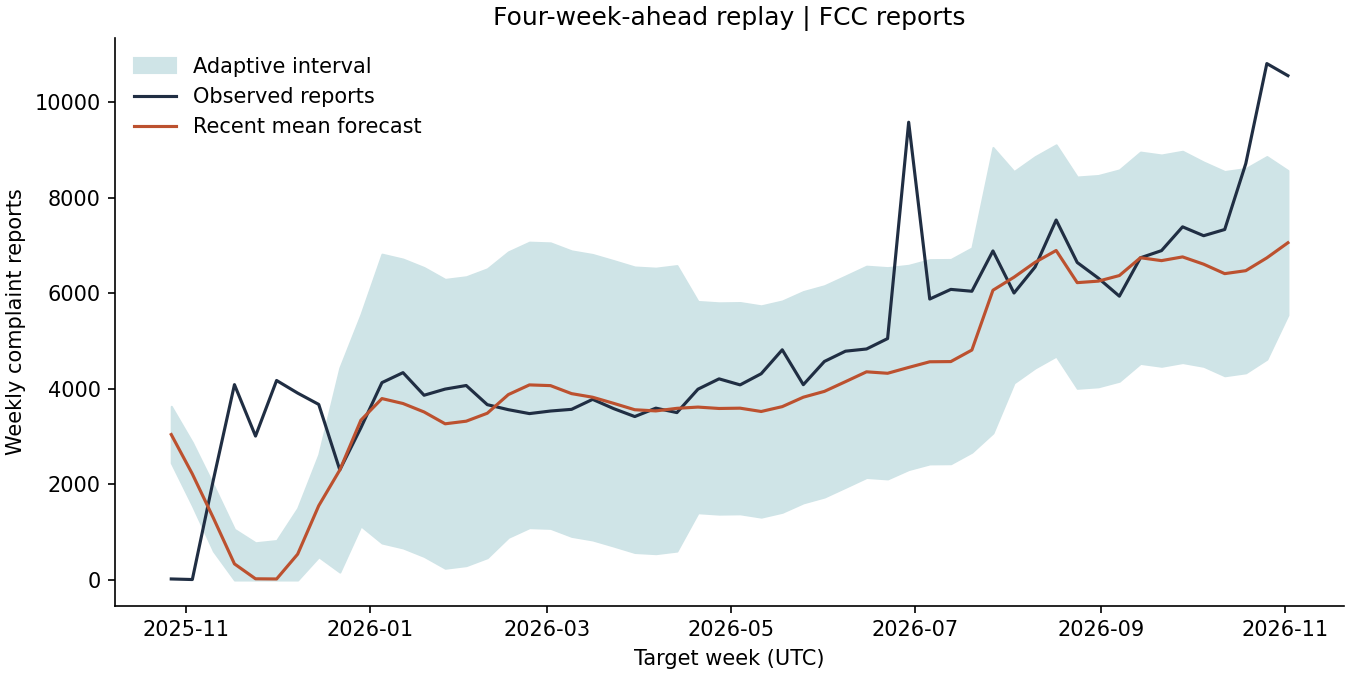

In [4]:
display(pd.read_csv(r/'periods.csv'))
display(pd.read_csv(r/'paired_blocks.csv'))
display(Image(filename=str(r/'timeline.png')))

## Change the assumptions
The two-week lag delays both fresh features and score feedback. The issue-mix sensitivity removes reports with the exact Unwanted Calls label. Both reuse the development-selected gain.

In [5]:
display(pd.read_csv(r/'sensitivity.csv'))
display(pd.read_csv(r/'point_baselines.csv'))

,horizon,method,n,covered,coverage,width,score,upper_misses,lower_misses,variant
0,1,adaptive,54,43,0.796296,3647.138889,7536.537037,9,2,two_week_data_lag
1,1,frozen,54,39,0.722222,2148.666667,6043.157407,13,2,two_week_data_lag
2,1,rolling,54,42,0.777778,3289.824074,7309.916667,10,2,two_week_data_lag
3,4,adaptive,54,42,0.777778,5907.828704,9295.745370,9,3,two_week_data_lag
4,4,frozen,54,33,0.611111,2029.259259,7873.194444,19,2,two_week_data_lag
5,4,rolling,54,39,0.722222,3476.629630,8309.685185,12,3,two_week_data_lag
6,1,adaptive,54,46,0.851852,1407.657407,2969.648148,7,1,exclude_unwanted_calls
7,1,frozen,54,17,0.314815,227.902778,3516.328704,23,14,exclude_unwanted_calls
8,1,rolling,54,41,0.759259,978.236111,2829.347222,10,3,exclude_unwanted_calls
9,4,adaptive,54,44,0.814815,2667.013889,4712.060185,8,2,exclude_unwanted_calls


,horizon,recent_error,seasonal_error
0,1,695.601852,2411.740741
1,4,1076.277778,2411.740741


## Decision
Keep a simple interval reference and instrument direction of misses by horizon and arrival vintage. The historical snapshot cannot establish what had actually been published on each forecast date. Review the report and run the builder exercises before reusing this workflow.